# NFIP Flood Insurance Claims: EDA and Feature Selection

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

**Dataset:** FEMA *NFIP Redacted Claims v3* (OpenFEMA, public domain). One row is one flood insurance claim.
We use claims with a loss date between 2020 and 2025.

**Our three research questions**

| RQ | Question | Family | Target |
|---|---|---|---|
| RQ1 | How much will FEMA pay for the building? | Regression | `amountPaidOnBuildingClaim` |
| RQ2 | Is this a high-severity claim (top 20% of building damage)? | Classification | `high_severity` (built from `buildingDamageAmount`) |
| RQ3 | Do claims form groups with similar flood risk? | Clustering + PCA | no target |

**Plan of this notebook**

0. Load the data and take a first look
1. Attribute types
2. Missing values
3. Duplicates
4. Columns we drop
5. Filling missing values (imputation)
6. Outliers and noise
7. New features
8. Encoding and scaling
9. Feature selection
10. Summary

There is no separate "charts" section. Each chart appears in the step where it helps us decide something,
and each chart type matches the column type.

---
# Section 0: Setup and First Look

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
print('ready')

ready


In [2]:
DATA_path = "/Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet"

full = pd.read_parquet(DATA_path)
print('Rows in the full national file :', f'{len(full):,}')
print('Columns                        :', full.shape[1])

# Keep only claims with a loss year between 2020 and 2025
df = full[full['yearOfLoss'].between(2020, 2025)].reset_index(drop=True)
del full
print('Rows we keep (2020-2025)       :', f'{len(df):,}')

Rows in the full national file : 2,725,989
Columns                        : 84


Rows we keep (2020-2025)       : 277,033


The file stores money values as `Decimal` objects and dates as text-like objects.
We convert them first. Otherwise pandas cannot calculate with them.

In [3]:
MONEY_COLS = ['amountPaidOnBuildingClaim', 'amountPaidOnContentsClaim', 'amountPaidOnIncreasedCostOfComplianceClaim',
              'netBuildingPaymentAmount', 'netContentsPaymentAmount', 'netIccPaymentAmount',
              'baseFloodElevation', 'lowestAdjacentGrade', 'lowestFloorElevation', 'latitude', 'longitude',
              'totalSalvageRecovery', 'totalBldgClaimPmtRecovery', 'totalContentsClaimPmtRecovery',
              'totalIccClaimPmtRecovery', 'totalSubrogationRecovery']
DATE_COLS = ['dateOfLoss', 'originalConstructionDate', 'originalNBDate', 'openDate',
             'mostRecentPaymentDate', 'mostRecentRecoveryDate']

for c in MONEY_COLS:
    df[c] = df[c].astype(float)
for c in DATE_COLS:
    d = pd.to_datetime(df[c].astype(str), format='%Y-%m-%d', errors='coerce')
    d = d.where(d.dt.year >= 1800)                     # impossible dates (e.g. year 1069) become NaT
    df[c] = d.astype('datetime64[ns]')

print('Date range of dateOfLoss:', df['dateOfLoss'].min().date(), 'to', df['dateOfLoss'].max().date())
print()
print('Claims per year:')
print(df['yearOfLoss'].value_counts().sort_index())

Date range of dateOfLoss: 2020-01-01 to 2025-12-31

Claims per year:
yearOfLoss
2020     33185
2021     46699
2022     60262
2023     21690
2024    102054
2025     13143
Name: count, dtype: int64


**Note:** the data is a snapshot from September 2026. Claims from 2025 are still being added, so 2025 looks small.

**First look: when and where do claims happen?** A date is an *interval* column, so we use a bar per month (time order).
State is *nominal*, so we use a bar chart of counts.

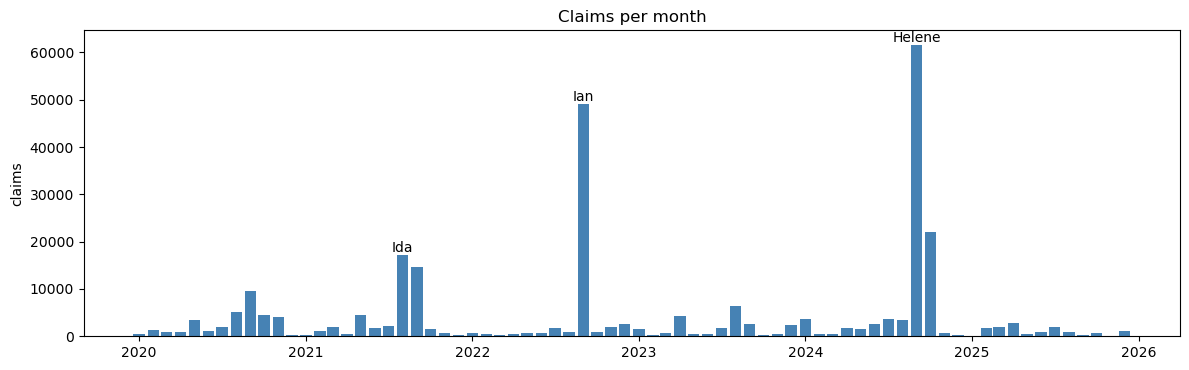

A few hurricanes create most of the claims.


In [4]:
# Chart (interval, time): claims per month
monthly = df.groupby(df['dateOfLoss'].dt.to_period('M')).size()
monthly.index = monthly.index.to_timestamp()
plt.figure(figsize=(12, 3.8))
plt.bar(monthly.index, monthly.values, width=25, color='steelblue')
plt.title('Claims per month'); plt.ylabel('claims')
for name, date in [('Ida', '2021-08-01'), ('Ian', '2022-09-01'), ('Helene', '2024-09-01')]:
    plt.annotate(name, (pd.Timestamp(date), monthly.get(pd.Timestamp(date), 0)), ha='center', va='bottom')
plt.tight_layout(); plt.show()
print('A few hurricanes create most of the claims.')

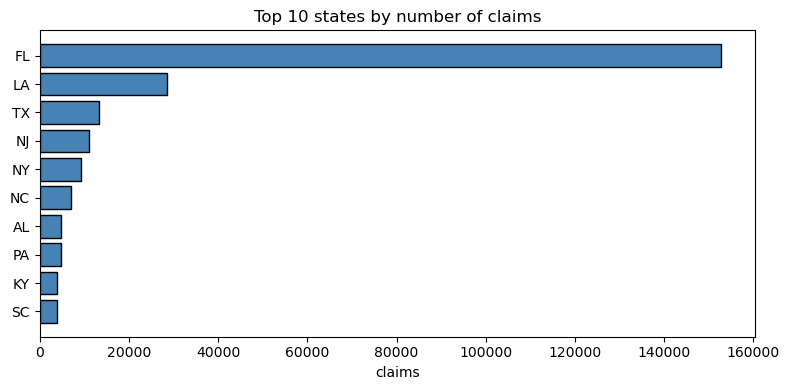

Florida has 55% of all claims.


In [5]:
# Chart (nominal): claims by state
top = df['state'].value_counts().head(10)
plt.figure(figsize=(8, 4))
plt.barh(top.index[::-1], top.values[::-1], color='steelblue', edgecolor='black')
plt.title('Top 10 states by number of claims'); plt.xlabel('claims')
plt.tight_layout(); plt.show()
print(f"Florida has {top['FL'] / len(df):.0%} of all claims.")

Two facts to remember for the whole project: a few hurricanes create most of the claims, and Florida has more than half of them.

---
# Section 1: Attribute Types

Every column has a type. The type decides how we encode it and which chart we use.

- **Nominal:** names or codes with no order (state, flood zone)
- **Binary:** nominal with only two values (True / False)
- **Ordinal:** codes with an order (CRS class 1 to 10)
- **Interval:** numbers where zero is not "nothing" (dates, elevation, water depth can be negative)
- **Ratio:** numbers with a real zero (dollars, counts)

In [6]:
NOMINAL = ['ratedFloodZone', 'floodZoneCurrent', 'occupancyType', 'foundationType', 'basementEnclosureCrawlspaceType',
           'locationOfContents', 'obstructionType', 'buildingDescriptionCode', 'condominiumCoverageTypeCode',
           'elevationCertificateIndicator', 'disasterAssistanceCoverageRequired', 'rateMethod', 'causeOfDamage',
           'floodCharacteristicsIndicator', 'replacementCostBasis', 'floodEvent', 'eventDesignationNumber', 'ficoNumber',
           'nonPaymentReasonBuilding', 'nonPaymentReasonContents', 'state', 'reportedCity', 'reportedZipCode', 'countyCode',
           'censusGeoid', 'nfipRatedCommunityNumber', 'nfipCommunityNumberCurrent', 'nfipCommunityName', 'id']
BINARY = [c for c in df.columns if df[c].dtype == bool]
ORDINAL = ['crsClassCode', 'buildingDeductibleCode', 'contentsDeductibleCode', 'numberOfFloorsInTheInsuredBuilding']
INTERVAL = ['dateOfLoss', 'yearOfLoss', 'openDate', 'originalConstructionDate', 'originalNBDate', 'mostRecentPaymentDate',
            'mostRecentRecoveryDate', 'asOfDate', 'elevationDifference', 'baseFloodElevation', 'lowestFloorElevation',
            'lowestAdjacentGrade', 'waterDepth', 'interiorWaterDepth', 'exteriorWaterDepth', 'latitude', 'longitude']
RATIO = [c for c in df.columns if c not in NOMINAL + BINARY + ORDINAL + INTERVAL]

types = pd.DataFrame({'type': ['nominal'] * len(NOMINAL) + ['binary'] * len(BINARY) + ['ordinal'] * len(ORDINAL)
                              + ['interval'] * len(INTERVAL) + ['ratio'] * len(RATIO)},
                     index=NOMINAL + BINARY + ORDINAL + INTERVAL + RATIO)
print('Columns per type:')
print(types['type'].value_counts())
print()
print('Ratio columns:', RATIO)

Columns per type:
type
nominal     29
ratio       23
interval    17
binary      11
ordinal      4
Name: count, dtype: int64

Ratio columns: ['policyCount', 'amountPaidOnBuildingClaim', 'amountPaidOnContentsClaim', 'amountPaidOnIncreasedCostOfComplianceClaim', 'totalBuildingInsuranceCoverage', 'totalContentsInsuranceCoverage', 'buildingDamageAmount', 'netBuildingPaymentAmount', 'buildingPropertyValue', 'contentsDamageAmount', 'netContentsPaymentAmount', 'contentsPropertyValue', 'floodWaterDuration', 'iccCoverage', 'netIccPaymentAmount', 'numberOfUnits', 'buildingReplacementCost', 'contentsReplacementCost', 'totalSalvageRecovery', 'totalBldgClaimPmtRecovery', 'totalContentsClaimPmtRecovery', 'totalIccClaimPmtRecovery', 'totalSubrogationRecovery']


**How did we decide each type?** We looked at the values themselves. The table below shows, for every column,
how many different values it has and three example values. For example:
- `state` has text labels (FL, LA, TX) → nominal
- `crsClassCode` has the numbers 1 to 10, where 1 is best and 10 is worst → ordinal (an order, but no real distance)
- `waterDepth` can be negative (water below the floor) → interval, zero is not "no water level"
- `totalBuildingInsuranceCoverage` is in dollars and $0 means "no coverage" → ratio

In [7]:
evidence = pd.DataFrame({
    'type': types['type'],
    'dtype': df[types.index].dtypes.astype(str),
    'unique values': df[types.index].nunique(),
    'example values': [df[c].dropna().unique()[:3].tolist() for c in types.index],
})
print('Proof for ordinal: crsClassCode values =', sorted(df['crsClassCode'].dropna().unique()))
print('Proof for interval: smallest waterDepth =', df['waterDepth'].min(), ' (negative is possible)')
print('Proof for ratio: building coverage has true zeros =', (df['totalBuildingInsuranceCoverage'] == 0).sum(), 'rows')
evidence.sort_values('type')

Proof for ordinal: crsClassCode values = [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0)]
Proof for interval: smallest waterDepth = -207.0  (negative is possible)
Proof for ratio: building coverage has true zeros = 6518 rows


,type,dtype,unique values,example values
elevatedBuildingIndicator,binary,bool,2,"[False, True]"
houseWorship,binary,bool,2,"[False, True]"
nonProfitIndicator,binary,bool,2,"[False, True]"
postFIRMConstructionIndicator,binary,bool,2,"[False, True]"
smallBusinessIndicatorBuilding,binary,bool,2,"[False, True]"
...,...,...,...,...
amountPaidOnBuildingClaim,ratio,float64,195669,"[500000.0, 243827.07, 13920.08]"
policyCount,ratio,int16,258,"[1, 2, 6]"
totalIccClaimPmtRecovery,ratio,float64,3,"[0.0, 6150.0, 12000.0]"
netContentsPaymentAmount,ratio,float64,71140,"[0.0, 682.11, 1124.45]"


We have all four types (plus binary), so encoding choices will matter later.

---
# Section 2: Missing Values

## 2.1 How much is missing?

In [8]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
summary = pd.DataFrame({'missing': miss, 'percent': (miss / len(df) * 100).round(1)})
print('Columns with missing values:', len(summary), 'of', df.shape[1])
print(summary)

Columns with missing values: 57 of 84
                                            missing  percent
floodCharacteristicsIndicator                277033    100.0
ficoNumber                                   277033    100.0
totalIccClaimPmtRecovery                     276630     99.9
totalContentsClaimPmtRecovery                276630     99.9
totalBldgClaimPmtRecovery                    276630     99.9
totalSalvageRecovery                         276630     99.9
mostRecentRecoveryDate                       276630     99.9
totalSubrogationRecovery                     276630     99.9
floodWaterDuration                           261438     94.4
elevationCertificateIndicator                242913     87.7
nonPaymentReasonBuilding                     222102     80.2
obstructionType                              217295     78.4
disasterAssistanceCoverageRequired           184287     66.5
baseFloodElevation                           182949     66.0
elevationDifference                          18

In [9]:
# What would dropna() cost?
print(f"Rows now            : {len(df):>8,}")
print(f"Rows after dropna() : {len(df.dropna()):>8,}")
print()
print('Every row has at least one blank. We cannot just delete rows.')

Rows now            :  277,033


Rows after dropna() :        0

Every row has at least one blank. We cannot just delete rows.


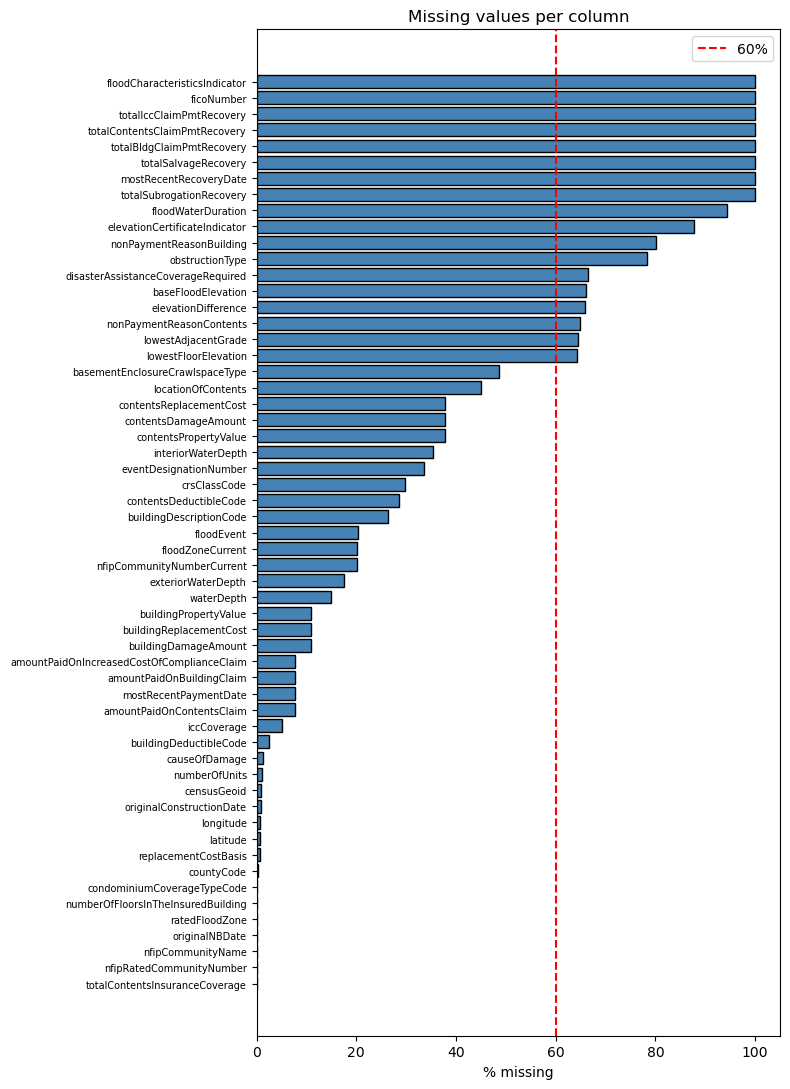

In [10]:
plt.figure(figsize=(8, 11))
plt.barh(summary.index, summary['percent'], color='steelblue', edgecolor='black')
plt.axvline(60, color='red', ls='--', label='60%')
plt.gca().invert_yaxis()
plt.xlabel('% missing')
plt.title('Missing values per column')
plt.yticks(fontsize=7)
plt.legend(); plt.tight_layout(); plt.show()

## 2.2 Hidden missing values

Some "missing" values are not blank. They are stored as a fake number. We must find them before we count.

In [11]:
print('waterDepth values from 95 to 103 inches:')
print(df['waterDepth'].value_counts().sort_index().loc[95:103])
print()
print('99 appears thousands of times, but 98 and 100 are rare. 99 is a code for "unknown".')

waterDepth values from 95 to 103 inches:
waterDepth
95.0         8
96.0        28
97.0         3
98.0         5
99.0     12509
100.0        5
101.0        3
102.0        5
103.0        3
Name: count, dtype: int64

99 appears thousands of times, but 98 and 100 are rare. 99 is a code for "unknown".


In [12]:
has_bldg_cov = df['totalBuildingInsuranceCoverage'] > 0
print('Building value = $0 although the building is insured :', ((df['buildingPropertyValue'] == 0) & has_bldg_cov).sum())
print('Building damage = exactly $1                          :', (df['buildingDamageAmount'] == 1).sum())
print('   median payment on those "$1 damage" claims         :', f"${df.loc[df['buildingDamageAmount'] == 1, 'netBuildingPaymentAmount'].median():,.0f}")
print('Interior water depth >= 999 inches (83 feet!)         :', (df['interiorWaterDepth'] >= 999).sum())
print('reportedCity values                                   :', df['reportedCity'].unique())
print()
print('An insured house cannot be worth $0. A claim with $1 damage is not paid $47,000.')
print('These are placeholders. We turn them into NaN.')

Building value = $0 although the building is insured : 26773
Building damage = exactly $1                          : 2376
   median payment on those "$1 damage" claims         : $47,174
Interior water depth >= 999 inches (83 feet!)         : 3190
reportedCity values                                   : ['Currently Unavailable']

An insured house cannot be worth $0. A claim with $1 damage is not paid $47,000.
These are placeholders. We turn them into NaN.


In [13]:
df.loc[df['waterDepth'] == 99, 'waterDepth'] = np.nan
df.loc[df['interiorWaterDepth'] >= 999, 'interiorWaterDepth'] = np.nan
df.loc[df['exteriorWaterDepth'] >= 999, 'exteriorWaterDepth'] = np.nan
df.loc[(df['buildingPropertyValue'] == 0) & has_bldg_cov, 'buildingPropertyValue'] = np.nan
df.loc[(df['buildingReplacementCost'] == 0) & has_bldg_cov, 'buildingReplacementCost'] = np.nan
df.loc[df['buildingDamageAmount'] == 1, 'buildingDamageAmount'] = np.nan
print('Hidden missing values replaced with NaN.')

Hidden missing values replaced with NaN.


## 2.3 Which kind of missing is it?

The same blank cell can mean different things:

| Kind | Meaning | Example in our data |
|---|---|---|
| **Not applicable** | The value does not exist | No payment was made, so there is no payment amount |
| **Missing at random: no pattern** | Blank by pure chance | Policy start date missing on 0.02% of rows, same in every group |
| **Missing for a visible reason** | Blank depends on **another column we can see** | CRS class is missing more often on old-style policies |
| **Missing for a hidden reason** | Blank depends on **something we cannot see** | Water depth is missing when nobody inspected the house |

In statistics books these three are called **MCAR**, **MAR** and **MNAR** (in this order).

Rule: *only the "no pattern" kind is safe to simply fill in.*
For the other kinds we add a new category or keep a "was missing" flag.

Let's check the "not applicable" cases with numbers: we compare each blank column with a column that says the thing does not exist.

In [14]:
print('CHECK 1: payment amount blank  vs  net payment = 0')
blank = df['amountPaidOnBuildingClaim'].isna()
print('   blank payment amounts            :', blank.sum())
print('   of those, net payment is 0       :', (df.loc[blank, 'netBuildingPaymentAmount'] == 0).sum())
print('   -> the blank means $0 was paid.')
print()
print('CHECK 2: contents damage blank  vs  no contents insurance')
blank = df['contentsDamageAmount'].isna()
no_cont = df['totalContentsInsuranceCoverage'] == 0
print('   blank contents damage            :', blank.sum())
print('   of those, no contents insurance  :', (blank & no_cont).sum(), f'({(blank & no_cont).sum() / blank.sum():.0%})')
print('   -> most blanks mean "no contents insured". The rest were not recorded.')
print()
print('CHECK 3: obstruction type blank  vs  building not elevated')
blank = df['obstructionType'].isna()
print('   blank obstruction type           :', blank.sum())
print('   of those, building not elevated  :', (blank & ~df['elevatedBuildingIndicator']).sum())
print('   -> obstruction type only exists for elevated buildings.')
print()
print('CHECK 4: non-payment reason blank  vs  claim was paid')
blank = df['nonPaymentReasonBuilding'].isna()
paid_b = df['netBuildingPaymentAmount'] > 0
print('   blank non-payment reason         :', blank.sum())
print('   of those, the claim was paid     :', (blank & paid_b).sum(), f'({(blank & paid_b).sum() / blank.sum():.0%})')
print('   -> a paid claim needs no "reason for not paying".')
print()
print('CHECK 5: floodEvent blank  vs  eventDesignationNumber blank')
blank = df['floodEvent'].isna()
print('   blank floodEvent                 :', blank.sum())
print('   of those, no event number either :', (blank & df['eventDesignationNumber'].isna()).sum())
print('   -> no storm was named for these claims.')
print()
print('CHECK 6: recovery amount blank  vs  recovery date blank')
blank = df['totalBldgClaimPmtRecovery'].isna()
print('   blank recovery amount            :', blank.sum())
print('   of those, no recovery date       :', (blank & df['mostRecentRecoveryDate'].isna()).sum())
print('   -> no money was ever recovered.')
print()
print('CHECK 7: building deductible blank  vs  no building insurance')
blank = df['buildingDeductibleCode'].isna()
no_bldg = df['totalBuildingInsuranceCoverage'] == 0
print('   blank building deductible        :', blank.sum())
print('   of those, no building insurance  :', (blank & no_bldg).sum(), f'({(blank & no_bldg).sum() / blank.sum():.0%})')
print('   -> contents-only policies have no building deductible.')

CHECK 1: payment amount blank  vs  net payment = 0
   blank payment amounts            : 21744
   of those, net payment is 0       : 21744
   -> the blank means $0 was paid.

CHECK 2: contents damage blank  vs  no contents insurance
   blank contents damage            : 104598
   of those, no contents insurance  : 62048 (59%)
   -> most blanks mean "no contents insured". The rest were not recorded.

CHECK 3: obstruction type blank  vs  building not elevated
   blank obstruction type           : 217295
   of those, building not elevated  : 215959
   -> obstruction type only exists for elevated buildings.

CHECK 4: non-payment reason blank  vs  claim was paid
   blank non-payment reason         : 222102
   of those, the claim was paid     : 212253 (96%)
   -> a paid claim needs no "reason for not paying".

CHECK 5: floodEvent blank  vs  eventDesignationNumber blank
   blank floodEvent                 : 56474
   of those, no event number either : 56474
   -> no storm was named for these c

In [15]:
# A "visible reason" check: does missingness depend on the rating system (rateMethod 'RE' = new Risk Rating 2.0)?
df['rating_system'] = np.where(df['rateMethod'] == 'RE', 'Risk Rating 2.0', 'legacy')
check = df.groupby('rating_system')[['crsClassCode', 'basementEnclosureCrawlspaceType', 'elevationDifference']].apply(
    lambda g: g.isna().mean() * 100).round(1)
print('% missing by rating system:')
print(check.T)
print()
print('crsClassCode is missing much more often on legacy policies.')
print('The blank depends on a column we can see (rateMethod).')
print('That is "missing for a visible reason" (MAR).')

% missing by rating system:
rating_system                    Risk Rating 2.0  legacy
crsClassCode                                25.9    64.2
basementEnclosureCrawlspaceType             49.5    41.6
elevationDifference                         65.2    71.2

crsClassCode is missing much more often on legacy policies.
The blank depends on a column we can see (rateMethod).
That is "missing for a visible reason" (MAR).


In [16]:
# A "hidden reason" check: is a claim with missing water depth different?
paid = df['netBuildingPaymentAmount'] > 0
print('Share of claims that were paid:')
print(f"   water depth recorded : {paid[df['waterDepth'].notna()].mean():.0%}")
print(f"   water depth missing  : {paid[df['waterDepth'].isna()].mean():.0%}")
print()
print('Claims without a water depth are paid much less often.')
print('Probably no adjuster visited, because the damage was small. The reason is not in any column,')
print('so this is "missing for a hidden reason" (MNAR). We keep a "was missing" flag.')

Share of claims that were paid:
   water depth recorded : 82%
   water depth missing  : 56%

Claims without a water depth are paid much less often.
Probably no adjuster visited, because the damage was small. The reason is not in any column,
so this is "missing for a hidden reason" (MNAR). We keep a "was missing" flag.


**One evidence table for all the other columns.** For each column we compare:
- **% missing on legacy vs Risk Rating 2.0 policies.** A big difference = the blank depends on a column we can see → *visible reason*.
- **% of claims paid when the value is blank vs present.** A big difference that the rating system does not explain = the blank is linked to the claim itself → *hidden reason*.
- **Small numbers everywhere and no differences** → *no pattern*.

In [17]:
legacy = df['rateMethod'] != 'RE'
paid_b = df['netBuildingPaymentAmount'] > 0
check_cols = ['crsClassCode', 'basementEnclosureCrawlspaceType', 'locationOfContents', 'foundationType', 'elevationDifference',
              'baseFloodElevation', 'waterDepth', 'interiorWaterDepth', 'exteriorWaterDepth', 'buildingDamageAmount',
              'buildingPropertyValue', 'causeOfDamage', 'replacementCostBasis', 'latitude', 'longitude', 'countyCode',
              'numberOfUnits', 'condominiumCoverageTypeCode', 'numberOfFloorsInTheInsuredBuilding', 'originalNBDate']
rows = []
for c in check_cols:
    m = df[c].isna()
    if c == 'foundationType':
        m = df[c] == '0'                      # code 0 = not recorded
    rows.append({'column': c,
                 '% missing': round(m.mean() * 100, 1),
                 '% missing legacy': round(m[legacy].mean() * 100, 1),
                 '% missing RR2.0': round(m[~legacy].mean() * 100, 1),
                 'paid % if blank': round(paid_b[m].mean() * 100, 1),
                 'paid % if present': round(paid_b[~m].mean() * 100, 1)})
miss_evidence = pd.DataFrame(rows).set_index('column')
miss_evidence['legacy - RR2 gap'] = (miss_evidence['% missing legacy'] - miss_evidence['% missing RR2.0']).round(1)
miss_evidence['paid gap'] = (miss_evidence['paid % if blank'] - miss_evidence['paid % if present']).round(1)
miss_evidence

,% missing,% missing legacy,% missing RR2.0,paid % if blank,paid % if present,legacy - RR2 gap,paid gap
column,,,,,,,
crsClassCode,29.8,64.2,25.9,75.6,77.4,38.3,-1.8
basementEnclosureCrawlspaceType,48.7,41.6,49.5,77.6,76.1,-7.9,1.5
locationOfContents,45.0,35.5,46.0,78.6,75.4,-10.5,3.2
foundationType,9.5,93.3,0.0,69.8,77.6,93.3,-7.8
elevationDifference,65.8,71.2,65.2,77.7,75.2,6.0,2.5
baseFloodElevation,66.0,71.4,65.4,77.7,75.2,6.0,2.5
waterDepth,19.6,20.4,19.5,55.6,82.0,0.9,-26.4
interiorWaterDepth,36.4,56.0,34.2,48.1,93.3,21.8,-45.2
exteriorWaterDepth,18.6,24.8,17.9,15.1,91.0,6.9,-75.9


**Reading the table**
- `crsClassCode` and `foundationType` (code 0): a very big **legacy vs RR2 gap**. The rating system explains the blank → visible reason.
- `basementEnclosureCrawlspaceType`, `locationOfContents`: a smaller rating gap (about 8-10 points) but almost no paid gap → visible reason.
- Water depths, `buildingDamageAmount`, `buildingPropertyValue`: a **very big paid gap** (paid much less often when blank),
  and the rating gap does not explain it → hidden reason (no adjuster visit, small claims).
- The elevation columns: missing on most claims in **both** rating systems, and paid gap is small.
  They are missing because no Elevation Certificate was filed (a policy document) → visible reason.
- `causeOfDamage`, `replacementCostBasis`: only 12-21% of claims are paid when these are blank → hidden reason (the claim was closed early).
- `latitude`, `longitude`, `countyCode`, `numberOfUnits`, condo type, number of floors: under 1% missing overall,
  but the blanks are almost all on **legacy** policies (1-10% there vs about 0% on RR2.0) → visible reason.
  Because they are so few, a simple fill (median or mode) changes almost nothing.
- `originalNBDate`: 0.02% missing, the same in both rating systems, and almost no paid gap.
  This is the only clear **no pattern** column. A real lesson: in this data, "no pattern" is rare.

In [18]:
kinds = pd.DataFrame([
    ('amountPaidOn* (3 columns)', 'not applicable', 'no payment made -> fill 0'),
    ('contentsDamageAmount / contentsPropertyValue', 'not applicable + hidden reason', 'no contents cover -> 0; rest stays blank'),
    ('obstructionType', 'not applicable', 'building not elevated -> "not_applicable"'),
    ('nonPaymentReason* (2 columns)', 'not applicable', 'claim was paid -> no reason needed'),
    ('floodEvent', 'not applicable', 'no named storm -> "no_named_event"'),
    ('recovery columns (6 columns)', 'not applicable', 'no money recovered'),
    ('crsClassCode', 'visible reason (MAR)', 'depends on rating system'),
    ('basementEnclosureCrawlspaceType, locationOfContents', 'visible reason (MAR)', 'depends on rating system / policy form'),
    ('elevation columns (4 columns)', 'visible reason (MAR)', 'no Elevation Certificate filed'),
    ('waterDepth, interior/exteriorWaterDepth', 'hidden reason (MNAR)', 'not measured, often small claims'),
    ('buildingDamageAmount / PropertyValue / ReplacementCost', 'hidden reason (MNAR)', 'no adjuster valuation'),
    ('causeOfDamage, replacementCostBasis', 'hidden reason (MNAR)', 'claim closed early -> "unknown"'),
    ('buildingDeductibleCode', 'not applicable', 'contents-only policy -> no deductible'),
    ('latitude, longitude, countyCode, numberOfUnits, condo type, floors', 'visible reason (MAR), under 1%', 'mostly legacy policies; so few that median/mode is fine'),
    ('originalNBDate', 'no pattern (MCAR)', '0.02%, same everywhere'),
    ('ficoNumber, floodCharacteristicsIndicator, reportedCity', 'empty', '100% blank or redacted'),
], columns=['column', 'kind of missing', 'reason'])
kinds['proof'] = ['CHECK 1', 'CHECK 2', 'CHECK 3', 'CHECK 4', 'CHECK 5', 'CHECK 6',
                  'evidence table: rating gap', 'evidence table: rating gap', 'evidence table: missing in both systems',
                  'evidence table: paid gap', 'evidence table: paid gap', 'evidence table: paid gap', 'CHECK 7',
                  'evidence table: rating gap', 'evidence table: no gap', 'Section 2.1 (100% blank)']
kinds

,column,kind of missing,reason,proof
0,amountPaidOn* (3 columns),not applicable,no payment made -> fill 0,CHECK 1
1,contentsDamageAmount / contentsPropertyValue,not applicable + hidden reason,no contents cover -> 0; rest stays blank,CHECK 2
2,obstructionType,not applicable,"building not elevated -> ""not_applicable""",CHECK 3
3,nonPaymentReason* (2 columns),not applicable,claim was paid -> no reason needed,CHECK 4
4,floodEvent,not applicable,"no named storm -> ""no_named_event""",CHECK 5
5,recovery columns (6 columns),not applicable,no money recovered,CHECK 6
6,crsClassCode,visible reason (MAR),depends on rating system,evidence table: rating gap
7,"basementEnclosureCrawlspaceType, locationOfCon...",visible reason (MAR),depends on rating system / policy form,evidence table: rating gap
8,elevation columns (4 columns),visible reason (MAR),no Elevation Certificate filed,evidence table: missing in both systems
9,"waterDepth, interior/exteriorWaterDepth",hidden reason (MNAR),"not measured, often small claims",evidence table: paid gap


---
# Section 3: Duplicates

Decide what "the same" means before deleting.
`id` is unique for every row, so we compare **all columns except `id`**.

In [19]:
cols_no_id = [c for c in df.columns if c != 'id']
print('Duplicate id values                     :', df['id'].duplicated().sum())
print('Exact duplicate rows (all columns)      :', df.duplicated().sum())
print('Duplicate rows (all columns except id)  :', df.duplicated(subset=cols_no_id).sum())

Duplicate id values                     : 0


Exact duplicate rows (all columns)      : 0


Duplicate rows (all columns except id)  : 463


In [20]:
dups = df[df.duplicated(subset=cols_no_id, keep=False)]
print('Example: two rows that are the same except for id')
print(dups.sort_values(['state', 'dateOfLoss', 'censusGeoid']).head(2)[
    ['id', 'state', 'dateOfLoss', 'censusGeoid', 'originalConstructionDate', 'totalBuildingInsuranceCoverage', 'netBuildingPaymentAmount']])
print()
print('Same place, same date, same building age, same coverage, same payment.')
print('This is the same claim entered twice. We keep the first copy.')

Example: two rows that are the same except for id
             id state dateOfLoss   censusGeoid originalConstructionDate  \
50475   5945570    AL 2020-09-15  010970072032               1958-07-01   
109206  6524889    AL 2020-09-15  010970072032               1958-07-01   

        totalBuildingInsuranceCoverage  netBuildingPaymentAmount  
50475                         500000.0                       0.0  
109206                        500000.0                       0.0  

Same place, same date, same building age, same coverage, same payment.
This is the same claim entered twice. We keep the first copy.


In [21]:
before = len(df)
df = df.drop_duplicates(subset=cols_no_id).reset_index(drop=True)
print(f'Rows before: {before:,}   after: {len(df):,}   removed: {before - len(df)}')

Rows before: 277,033   after: 276,570   removed: 463


---
# Section 4: Columns We Drop

A column is dropped when it cannot help, or when it would **cheat** (leakage).
Leakage = the column is only known *after* the claim is paid, so it gives away the answer.

In [22]:
# near-constant columns: one value in 99.5% or more of rows
top_share = df.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
print('Columns where one value fills 99.5% or more of rows:')
print(top_share[top_share >= 0.995].round(4).sort_values(ascending=False))

Columns where one value fills 99.5% or more of rows:
asOfDate                         1.0000
ficoNumber                       1.0000
floodCharacteristicsIndicator    1.0000
floodproofedIndicator            1.0000
reportedCity                     1.0000
agricultureStructureIndicator    0.9997
stateOwnedIndicator              0.9997
houseWorship                     0.9989
mostRecentRecoveryDate           0.9985
totalSalvageRecovery             0.9985
totalBldgClaimPmtRecovery        0.9985
totalContentsClaimPmtRecovery    0.9985
totalIccClaimPmtRecovery         0.9985
totalSubrogationRecovery         0.9985
netIccPaymentAmount              0.9962
dtype: float64


In [23]:
DROP = {
    # empty
    'ficoNumber': 'empty (100% missing)', 'floodCharacteristicsIndicator': 'empty (100% missing)',
    'reportedCity': 'empty (always "Currently Unavailable")',
    # constant or almost constant
    'asOfDate': 'constant', 'iccCoverage': 'constant', 'floodproofedIndicator': 'almost constant',
    'agricultureStructureIndicator': 'almost constant', 'stateOwnedIndicator': 'almost constant', 'houseWorship': 'almost constant',
    'disasterAssistanceCoverageRequired': 'too many missing and almost constant',
    # too many missing
    'floodWaterDuration': 'too many missing', 'elevationCertificateIndicator': 'too many missing',
    'baseFloodElevation': 'too many missing', 'lowestFloorElevation': 'too many missing', 'lowestAdjacentGrade': 'too many missing',
    # identifiers / too many categories
    'id': 'identifier', 'nfipCommunityName': 'text name, too many values', 'nfipRatedCommunityNumber': 'id-like, too many values',
    'nfipCommunityNumberCurrent': 'id-like, too many values', 'reportedZipCode': 'too many values', 'censusGeoid': 'too many values',
    'countyCode': 'too many values (state is kept instead)',
    # repeats another column
    'yearOfLoss': 'same as year of dateOfLoss', 'eventDesignationNumber': 'code for floodEvent',
    'floodZoneCurrent': 'repeats ratedFloodZone', 'preFirmIndicator': 'repeats postFIRMConstructionIndicator',
    'contentsReplacementCost': 'LEAKAGE (adjuster figure, known only after inspection)',
    # leakage: known only after payment
    'netBuildingPaymentAmount': 'LEAKAGE (payment)', 'netContentsPaymentAmount': 'LEAKAGE (payment)',
    'netIccPaymentAmount': 'LEAKAGE (payment)', 'amountPaidOnContentsClaim': 'LEAKAGE (payment)',
    'amountPaidOnIncreasedCostOfComplianceClaim': 'LEAKAGE (payment)', 'mostRecentPaymentDate': 'LEAKAGE (payment date)',
    'nonPaymentReasonBuilding': 'LEAKAGE (reason not paid)', 'nonPaymentReasonContents': 'LEAKAGE (reason not paid)',
    'mostRecentRecoveryDate': 'LEAKAGE (recovery)', 'totalSalvageRecovery': 'LEAKAGE (recovery)',
    'totalBldgClaimPmtRecovery': 'LEAKAGE (recovery)', 'totalContentsClaimPmtRecovery': 'LEAKAGE (recovery)',
    'totalIccClaimPmtRecovery': 'LEAKAGE (recovery)', 'totalSubrogationRecovery': 'LEAKAGE (recovery)',
}
drop_table = pd.DataFrame({'reason': DROP})

def group(reason):
    if 'LEAKAGE' in reason: return 'leakage'
    if 'empty' in reason: return 'empty'
    if 'constant' in reason: return 'constant or almost constant'
    if 'missing' in reason: return 'too many missing'
    if 'repeats' in reason or 'same as' in reason or 'code for' in reason: return 'repeats another column'
    return 'identifier / too many values'

drop_table['group'] = drop_table['reason'].map(group)
print('Columns dropped:', len(DROP))
print(drop_table['group'].value_counts())

Columns dropped: 41
group
leakage                         15
constant or almost constant      7
identifier / too many values     7
too many missing                 5
repeats another column           4
empty                            3
Name: count, dtype: int64


**Proof for each dropped column.** The numbers below are computed, not typed:
% missing, number of different values, and how often the most common value appears.

In [24]:
cols = list(DROP)
drop_table['% missing'] = (df[cols].isna().mean() * 100).round(1)
drop_table['unique values'] = df[cols].nunique()
drop_table['top value share %'] = (df[cols].apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0]) * 100).round(2)
drop_table.sort_values('group')

,reason,group,% missing,unique values,top value share %
asOfDate,constant,constant or almost constant,0.0,1,100.00
iccCoverage,constant,constant or almost constant,5.1,1,94.92
floodproofedIndicator,almost constant,constant or almost constant,0.0,2,100.00
agricultureStructureIndicator,almost constant,constant or almost constant,0.0,2,99.97
stateOwnedIndicator,almost constant,constant or almost constant,0.0,2,99.97
houseWorship,almost constant,constant or almost constant,0.0,2,99.89
disasterAssistanceCoverageRequired,too many missing and almost constant,constant or almost constant,66.5,5,66.52
ficoNumber,empty (100% missing),empty,100.0,0,100.00
floodCharacteristicsIndicator,empty (100% missing),empty,100.0,0,100.00
reportedCity,"empty (always ""Currently Unavailable"")",empty,0.0,1,100.00


## 4.1 Columns that repeat another column

Two columns that always say the same thing add no new information. We check each pair with a simple count.

In [25]:
print('Does one column repeat another?')
print(f"   yearOfLoss equals the year of dateOfLoss        : {(df['yearOfLoss'] == df['dateOfLoss'].dt.year).mean():.1%} of rows")
both = df['floodZoneCurrent'].notna()
print(f"   floodZoneCurrent equals ratedFloodZone          : {(df.loc[both, 'floodZoneCurrent'] == df.loc[both, 'ratedFloodZone']).mean():.1%} of rows")
per_event = df.dropna(subset=['eventDesignationNumber']).groupby('eventDesignationNumber')['floodEvent'].nunique()
print(f"   each eventDesignationNumber has one floodEvent  : {(per_event <= 1).mean():.0%} of event numbers")
print()
print('preFirmIndicator vs postFIRMConstructionIndicator:')
print(pd.crosstab(df['preFirmIndicator'], df['postFIRMConstructionIndicator']))
print('-> they are not simple opposites, so preFirm is unclear. postFIRM and building age carry the same idea.')

Does one column repeat another?
   yearOfLoss equals the year of dateOfLoss        : 100.0% of rows
   floodZoneCurrent equals ratedFloodZone          : 93.0% of rows
   each eventDesignationNumber has one floodEvent  : 100% of event numbers

preFirmIndicator vs postFIRMConstructionIndicator:
postFIRMConstructionIndicator   False  True 
preFirmIndicator                            
False                          118222  91132
True                            66996    220
-> they are not simple opposites, so preFirm is unclear. postFIRM and building age carry the same idea.


## 4.2 Leakage: columns that give away the answer

A leakage column is filled in **after** the payment decision. It would not exist when a new claim arrives,
so a model that uses it is reading the answer, not predicting it.

**How we found them:** we correlate every numeric column with the RQ1 target (building payment).
A correlation close to 1 means the column is almost the same number as the answer.
We also turn "is this field filled in?" into a 0/1 column, because some fields only exist after payment.

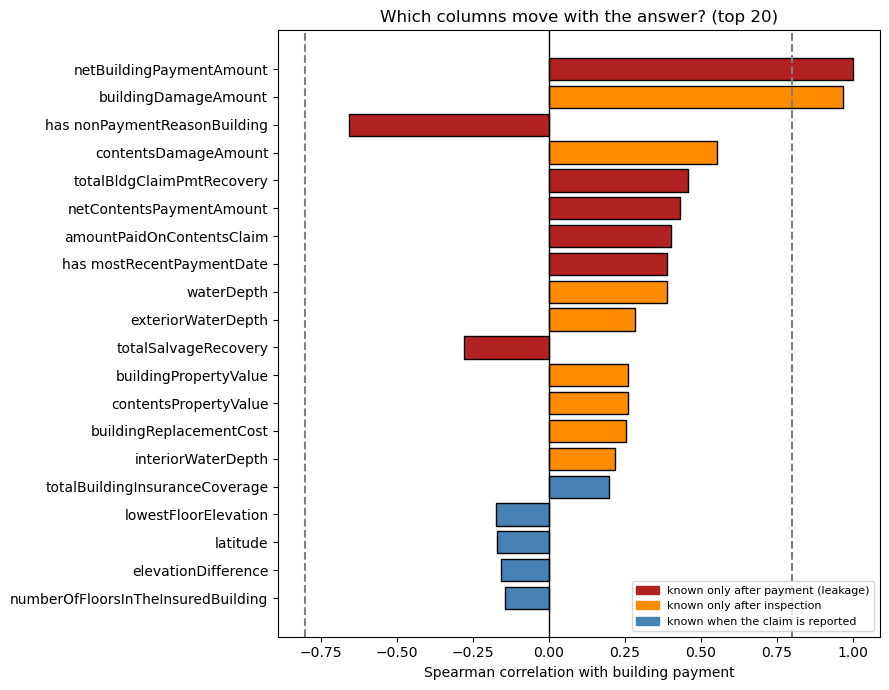

netBuildingPaymentAmount              1.000
buildingDamageAmount                  0.969
has nonPaymentReasonBuilding         -0.657
contentsDamageAmount                  0.554
totalBldgClaimPmtRecovery             0.458
netContentsPaymentAmount              0.433
amountPaidOnContentsClaim             0.402
has mostRecentPaymentDate             0.390
waterDepth                            0.389
exteriorWaterDepth                    0.284
totalSalvageRecovery                 -0.279
buildingPropertyValue                 0.262
contentsPropertyValue                 0.260
buildingReplacementCost               0.255
interiorWaterDepth                    0.217
totalBuildingInsuranceCoverage        0.200
lowestFloorElevation                 -0.173
latitude                             -0.170
elevationDifference                  -0.158
numberOfFloorsInTheInsuredBuilding   -0.143


In [26]:
target = df['amountPaidOnBuildingClaim'].fillna(0)            # blank payment = $0 paid (CHECK 1)

check = df.select_dtypes(include='number').drop(columns=['amountPaidOnBuildingClaim', 'id', 'yearOfLoss'])
check['has nonPaymentReasonBuilding'] = df['nonPaymentReasonBuilding'].notna().astype(int)
check['has mostRecentPaymentDate'] = df['mostRecentPaymentDate'].notna().astype(int)
check['has recovery amount'] = df['totalBldgClaimPmtRecovery'].notna().astype(int)
check = check.loc[:, check.nunique() > 1]                      # constant columns have no correlation

# Spearman = correlation of ranks, so a few huge dollar amounts cannot dominate
corr_with_target = check.corrwith(target, method='spearman').dropna()
top = corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index).head(20)

LEAK = ['netBuildingPaymentAmount', 'netContentsPaymentAmount', 'amountPaidOnContentsClaim', 'netIccPaymentAmount',
        'amountPaidOnIncreasedCostOfComplianceClaim', 'has nonPaymentReasonBuilding', 'has mostRecentPaymentDate',
        'has recovery amount', 'totalBldgClaimPmtRecovery', 'totalContentsClaimPmtRecovery', 'totalSalvageRecovery',
        'totalIccClaimPmtRecovery', 'totalSubrogationRecovery']
AFTER_INSPECTION = ['buildingDamageAmount', 'contentsDamageAmount', 'buildingPropertyValue', 'buildingReplacementCost',
                    'contentsPropertyValue', 'contentsReplacementCost', 'waterDepth', 'interiorWaterDepth', 'exteriorWaterDepth']
colors = ['firebrick' if c in LEAK else 'darkorange' if c in AFTER_INSPECTION else 'steelblue' for c in top.index]

plt.figure(figsize=(9, 7))
plt.barh(top.index[::-1], top.values[::-1], color=colors[::-1], edgecolor='black')
plt.axvline(0, color='black', lw=1)
plt.axvline(0.8, color='gray', ls='--'); plt.axvline(-0.8, color='gray', ls='--')
plt.xlabel('Spearman correlation with building payment')
plt.title('Which columns move with the answer? (top 20)')
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color='firebrick', label='known only after payment (leakage)'),
                    Patch(color='darkorange', label='known only after inspection'),
                    Patch(color='steelblue', label='known when the claim is reported')], loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

print(top.round(3).to_string())

In [27]:
paid_b = df['netBuildingPaymentAmount'] > 0
print('Two more checks for the 0/1 columns:')
print(f"   claims WITH a non-payment reason that were paid    : {paid_b[df['nonPaymentReasonBuilding'].notna()].mean():.1%}")
print(f"   claims WITHOUT a non-payment reason that were paid : {paid_b[df['nonPaymentReasonBuilding'].isna()].mean():.1%}")
print(f"   claims WITH a payment date that were paid           : {paid_b[df['mostRecentPaymentDate'].notna()].mean():.1%}")
print(f"   claims WITHOUT a payment date that were paid        : {paid_b[df['mostRecentPaymentDate'].isna()].mean():.1%}")

Two more checks for the 0/1 columns:
   claims WITH a non-payment reason that were paid    : 1.1%
   claims WITHOUT a non-payment reason that were paid : 95.6%
   claims WITH a payment date that were paid           : 83.5%
   claims WITHOUT a payment date that were paid        : 0.0%


**Reading the chart and the checks**
- **`netBuildingPaymentAmount` = 1.00.** It is the payment itself (minus small recoveries). Clear leakage.
- **`buildingDamageAmount` = 0.97.** Almost the same number as the payment. An adjuster measures it *after* the flood,
  so it is not available when a claim arrives. We use it only to build the RQ2 target, never as a feature.
- **`has nonPaymentReasonBuilding` = -0.66.** Strongly negative: only 1.1% of claims with a non-payment reason were paid.
  The field is written *because* the claim was not paid.
- **`has mostRecentPaymentDate` = 0.39.** The correlation looks only medium, because it measures how well the flag follows
  the *amount*. But the check shows **0% of claims without a payment date were paid**. The flag tells you perfectly
  *whether* a claim was paid. A correlation number alone can hide leakage, so we always check the meaning too.
- **Other red bars (contents payments, recoveries):** medium correlations, but they are all written after the payment. We drop them.
- **Blue bars (known when the claim is reported):** coverage, location and building facts are all below 0.25.
  These are the honest features for our models. They predict the payment much less well, and that is the truth.

In [28]:
# We need netBuildingPaymentAmount for one more step (filling the payment target), so we drop at the end of Section 5.
print('Columns before dropping:', df.shape[1])

Columns before dropping: 85


---
# Section 5: Filling Missing Values (Imputation)

We use different strategies for different kinds of missing:

| Strategy | Used for | Why |
|---|---|---|
| Fill with **0** | payment amount, contents damage with no contents insurance | the blank means $0 |
| New category **"unknown" / "not_applicable"** | basement type, obstruction type, contents location, cause of damage, ... | the blank carries information (visible or hidden reason); we don't invent a value |
| **Mode** (most common value) | small categorical gaps (< 1%, see the evidence table) | so few rows that it changes almost nothing |
| **Median** | small numeric gaps | median is safe with skewed data |
| **Group median** (median inside the same state) | latitude, longitude, building value, water depth | similar claims have similar values |
| **Not filled** | `buildingDamageAmount` | it is our RQ2 target. We never invent the answer |

In [29]:
work = df.copy()

# 1) Not applicable -> 0
blank_paid = work['amountPaidOnBuildingClaim'].isna() & (work['netBuildingPaymentAmount'] == 0)
work.loc[blank_paid, 'amountPaidOnBuildingClaim'] = 0
no_cont = work['totalContentsInsuranceCoverage'] == 0
for c in ['contentsDamageAmount', 'contentsPropertyValue']:
    work.loc[work[c].isna() & no_cont, c] = 0
print('Payment blanks filled with 0     :', blank_paid.sum())

# 2) Not applicable / unknown -> new category
work['obstructionType'] = work['obstructionType'].astype('Int64').astype(str)
work.loc[~work['elevatedBuildingIndicator'] & (work['obstructionType'] == '<NA>'), 'obstructionType'] = 'not_applicable'
for c in ['obstructionType', 'basementEnclosureCrawlspaceType', 'locationOfContents', 'buildingDescriptionCode']:
    work[c] = work[c].astype(str).replace({'nan': 'unknown', '<NA>': 'unknown'})
for c in ['causeOfDamage', 'replacementCostBasis', 'buildingDeductibleCode', 'contentsDeductibleCode']:
    work[c] = work[c].fillna('unknown')
work['floodEvent'] = work['floodEvent'].fillna('no_named_event')
print('Category columns now have "unknown" instead of blank.')

# 3) Mode for small categorical gaps
for c in ['condominiumCoverageTypeCode', 'numberOfFloorsInTheInsuredBuilding', 'ratedFloodZone', 'state']:
    work[c] = work[c].fillna(work[c].mode()[0])

# 4) Median for small numeric gaps
work['numberOfUnits'] = work['numberOfUnits'].fillna(work['numberOfUnits'].median())
work['totalContentsInsuranceCoverage'] = work['totalContentsInsuranceCoverage'].fillna(0)
print('Mode and median fills done.')

Payment blanks filled with 0     : 21558


Category columns now have "unknown" instead of blank.
Mode and median fills done.


## 5.1 Three ways to fill building value

`buildingPropertyValue` is missing on about 20% of claims. We compare:
1. global median
2. median inside the same **state**
3. KNN (the 5 most similar claims, using coverage and location)

In [30]:
bv = work['buildingPropertyValue']
print(f"Missing: {bv.isna().sum():,} of {len(work):,} ({bv.isna().mean() * 100:.1f} %)")
print()
print('Median building value by state (first 6):')
print(work.groupby('state')['buildingPropertyValue'].median().head(6))

Missing: 56,970 of 276,570 (20.6 %)

Median building value by state (first 6):
state
      210116.0
AK    282971.0
AL    208466.0
AR    164102.5
AS         NaN
AZ    202990.0
Name: buildingPropertyValue, dtype: float64


In [31]:
from sklearn.impute import KNNImputer

# Option 1: global median
opt1 = bv.fillna(bv.median())

# Option 2: median inside the same state
opt2 = work.groupby('state')['buildingPropertyValue'].transform(lambda s: s.fillna(s.median()))
opt2 = opt2.fillna(bv.median())

# Option 3: KNN on a sample of 20,000 claims (KNN is slow on 276k rows)
sample = work.sample(20000, random_state=42)
knn_cols = ['buildingPropertyValue', 'totalBuildingInsuranceCoverage', 'latitude', 'longitude', 'policyCount']
knn_in = sample[knn_cols].copy()
for c in ['buildingPropertyValue', 'totalBuildingInsuranceCoverage', 'policyCount']:
    knn_in[c] = np.log1p(knn_in[c])          # log, so big dollar numbers don't dominate the distance
knn_out = KNNImputer(n_neighbors=5).fit_transform(knn_in)
opt3 = pd.Series(np.expm1(knn_out[:, 0]), index=sample.index)

compare = pd.DataFrame({'original': bv, 'global median': opt1, 'state median': opt2}).describe().T
print(compare[['mean', 'std', '50%']].round(0))

                   mean        std       50%
original       664637.0  4705257.0  224288.0
global median  573931.0  4196509.0  224288.0
state median   575068.0  4196442.0  239271.0


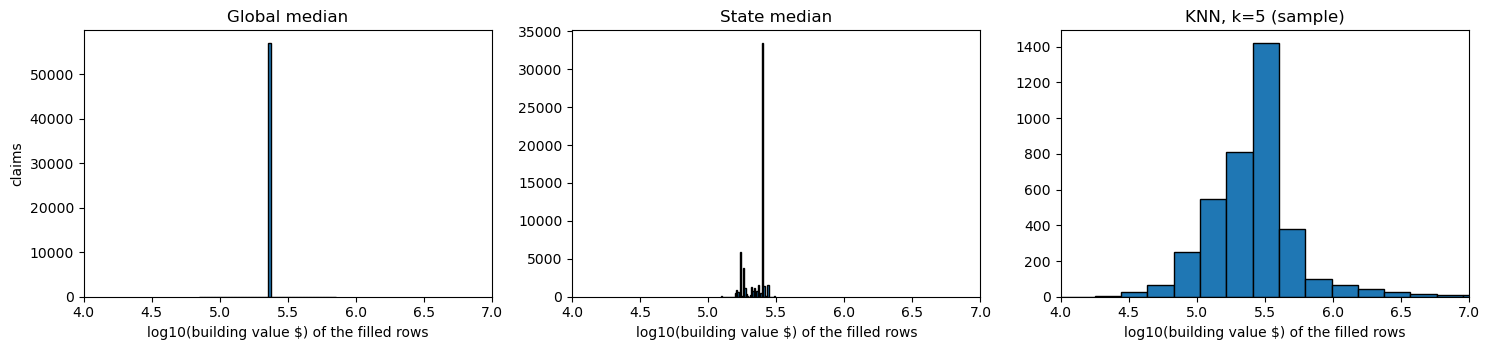

The global median gives every blank the same value: one tall spike.
State median and KNN give different values to different claims.


In [32]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
blank = bv.isna()
for a, (name, s) in zip(ax, [('Global median', opt1[blank]), ('State median', opt2[blank]),
                             ('KNN, k=5 (sample)', opt3[sample['buildingPropertyValue'].isna()])]):
    a.hist(np.log10(s.clip(lower=1)), bins=40, edgecolor='black')
    a.set_title(name); a.set_xlabel('log10(building value $) of the filled rows')
    a.set_xlim(4, 7)
ax[0].set_ylabel('claims')
plt.tight_layout(); plt.show()
print('The global median gives every blank the same value: one tall spike.')
print('State median and KNN give different values to different claims.')

**Decision:** we use the **state median**. It is simple, fast on all rows, and better than one global value.
KNN is similar but too slow for 276k rows on our laptops.
We also keep a flag `buildingPropertyValue_missing`, because the blank itself carries information (hidden reason).

In [33]:
for c in ['buildingPropertyValue', 'buildingReplacementCost', 'waterDepth', 'interiorWaterDepth', 'exteriorWaterDepth',
          'latitude', 'longitude', 'crsClassCode']:
    work[c + '_missing'] = work[c].isna().astype(int)
    work[c] = work.groupby('state')[c].transform(lambda s: s.fillna(s.median()))
    work[c] = work[c].fillna(work[c].median())          # safety net for states with no values

work = work.drop(columns=list(DROP))
print('Columns after dropping:', work.shape[1])
print()
left = work.isna().sum()
print('Columns that still have blanks (on purpose):')
print(left[left > 0])

Columns after dropping: 52

Columns that still have blanks (on purpose):
elevationDifference         182112
originalConstructionDate      2232
originalNBDate                  53
buildingDamageAmount         32709
contentsDamageAmount         42485
contentsPropertyValue        42485
dtype: int64


What is still blank is on purpose:
- `buildingDamageAmount`: the RQ2 target. Rows without it are not used for RQ2.
- `elevationDifference`: 66% missing. Only usable on the claims that have it.
- contents damage/value when contents were insured but not recorded.
- dates that were impossible (we turn them into ages in Section 7).

> For this EDA we filled values using all rows. In the modelling notebooks we will fit the fills on the training years only, so the test years stay unseen.

---
# Section 6: Outliers and Noise

- **Outlier:** a real value far from the others. We keep it.
- **Noise:** a wrong value. We find it with a rule and turn it into NaN.

In [34]:
pay = work.loc[work['amountPaidOnBuildingClaim'] > 0, 'amountPaidOnBuildingClaim']
print(f"Building payment min    : {pay.min():>14,.0f}")
print(f"Building payment median : {pay.median():>14,.0f}")
print(f"Building payment mean   : {pay.mean():>14,.0f}")
print(f"Building payment max    : {pay.max():>14,.0f}")
print(f"Skew                    : {pay.skew():>14.1f}")
print()
print('The mean is far above the median. A few very large claims pull it up.')
print('Five largest payments:')
print(work.nlargest(5, 'amountPaidOnBuildingClaim')[['amountPaidOnBuildingClaim', 'totalBuildingInsuranceCoverage', 'occupancyType', 'state']])
top5 = work.nlargest(5, 'amountPaidOnBuildingClaim')
print('Check: is each of these payments within the coverage bought?',
      (top5['amountPaidOnBuildingClaim'] <= top5['totalBuildingInsuranceCoverage']).tolist())
print('Occupancy 15 = condo association building. Big buildings, big coverage, payment within coverage.')
print('So these are real claims (outliers), not errors (noise). We keep them.')

Building payment min    :              2
Building payment median :         40,318
Building payment mean   :         76,471
Building payment max    :     10,741,477
Skew                    :           17.3

The mean is far above the median. A few very large claims pull it up.
Five largest payments:
        amountPaidOnBuildingClaim  totalBuildingInsuranceCoverage  \
71694                 10741476.93                      49500000.0   
98252                 10493402.34                      13500000.0   
235932                 9000000.00                       9000000.0   
105055                 8758773.33                      12032000.0   
167504                 7778936.86                      12750000.0   

        occupancyType state  
71694            15.0    FL  
98252            15.0    FL  
235932           15.0    FL  
105055           15.0    FL  
167504           15.0    FL  


Check: is each of these payments within the coverage bought? [True, True, True, True, True]
Occupancy 15 = condo association building. Big buildings, big coverage, payment within coverage.
So these are real claims (outliers), not errors (noise). We keep them.


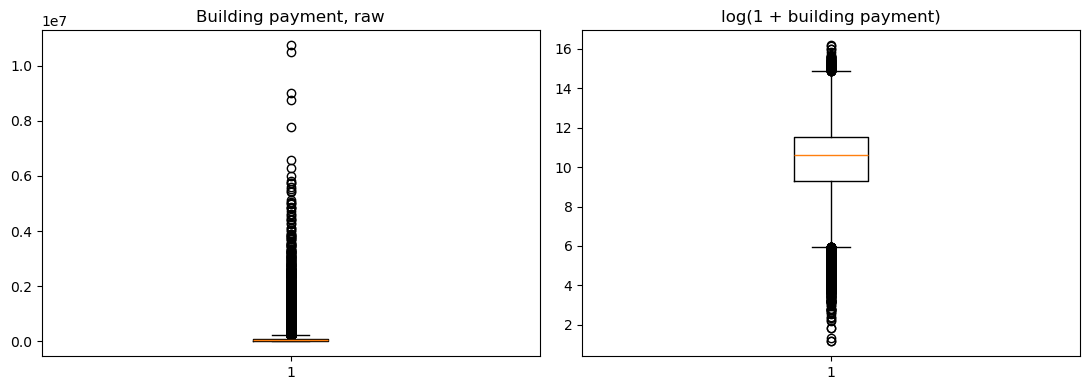

Same claims. Nothing deleted. The log transform makes the data readable.


In [35]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].boxplot(pay); ax[0].set_title('Building payment, raw')
ax[1].boxplot(np.log1p(pay)); ax[1].set_title('log(1 + building payment)')
plt.tight_layout(); plt.show()
print('Same claims. Nothing deleted. The log transform makes the data readable.')

In [36]:
# Noise rules
age_days = (work['dateOfLoss'] - work['originalConstructionDate']).dt.days
lag_days = (work['openDate'] - work['dateOfLoss']).dt.days
print('RULE 1: payment above the coverage bought    :', (work['amountPaidOnBuildingClaim'] > work['totalBuildingInsuranceCoverage'] + 1).sum())
print('RULE 2: negative payment                      :', (work['amountPaidOnBuildingClaim'] < 0).sum())
print('RULE 3: building built AFTER the flood        :', (age_days < 0).sum())
print('RULE 4: claim opened BEFORE the flood          :', (lag_days < 0).sum())
print('RULE 5: policy started AFTER the flood         :', (work['originalNBDate'] > work['dateOfLoss']).sum())

RULE 1: payment above the coverage bought    : 665
RULE 2: negative payment                      : 35
RULE 3: building built AFTER the flood        : 90
RULE 4: claim opened BEFORE the flood          : 56
RULE 5: policy started AFTER the flood         : 6339


In [37]:
# Fix: impossible values become NaN (or 0 for negative payments)
work['amountPaidOnBuildingClaim'] = work['amountPaidOnBuildingClaim'].clip(lower=0)
work.loc[age_days < 0, 'originalConstructionDate'] = pd.NaT
work.loc[work['originalNBDate'] > work['dateOfLoss'], 'originalNBDate'] = pd.NaT
over = work['amountPaidOnBuildingClaim'] > work['totalBuildingInsuranceCoverage'] + 1
work['paid_above_coverage'] = over.astype(int)
print('Noise fixed (impossible dates -> NaN, negative payments -> 0).')
print(f'Payments above coverage: {over.sum()} rows ({over.mean():.2%}).')
print(f"   of those, building coverage is $0: {(over & (work['totalBuildingInsuranceCoverage'] == 0)).sum()}")
print('We cannot tell from the data if they are errors or special cases, so we keep them and add a flag.')

Noise fixed (impossible dates -> NaN, negative payments -> 0).
Payments above coverage: 665 rows (0.24%).
   of those, building coverage is $0: 68
We cannot tell from the data if they are errors or special cases, so we keep them and add a flag.


---
# Section 7: New Features (Feature Engineering)

| New feature | How | Why it matters |
|---|---|---|
| `building_age` | loss date − construction date | older buildings were built before flood rules |
| `report_lag_days` | open date − loss date | late reports may mean small or disputed claims |
| `flood_zone_family` | 52 zone codes → 7 groups | FEMA's own risk groups (A, AE, V, X, ...) |
| `is_named_event` | named storm or not | hurricane claims are different |
| `log_paid_building` | log(1 + payment) | RQ1 target with less skew |
| `high_severity` | damage in the top 20% | RQ2 target |

In [38]:
work['building_age'] = (work['dateOfLoss'] - work['originalConstructionDate']).dt.days / 365.25
work['building_age'] = work['building_age'].fillna(work['building_age'].median())
work['report_lag_days'] = (work['openDate'] - work['dateOfLoss']).dt.days.clip(lower=0, upper=365)
work['report_lag_days'] = work['report_lag_days'].fillna(work['report_lag_days'].median())

def zone_family(z):
    z = str(z).upper()
    if z in ['X', 'B', 'C']: return 'X'
    if z.startswith('V'): return 'V'
    if z in ['AE', 'AH', 'AO', 'A99', 'A']: return z
    if z.startswith('A'): return 'AE'      # old codes A1-A30 are the same as AE
    return 'other'
work['flood_zone_family'] = work['ratedFloodZone'].map(zone_family)

work['is_named_event'] = (work['floodEvent'] != 'no_named_event').astype(int)
work['loss_month'] = work['dateOfLoss'].dt.month
work['log_paid_building'] = np.log1p(work['amountPaidOnBuildingClaim'])
work['is_paid'] = (work['amountPaidOnBuildingClaim'] > 0).astype(int)

threshold = work['buildingDamageAmount'].quantile(0.80)
work['high_severity'] = (work['buildingDamageAmount'] >= threshold).astype(int)
work.loc[work['buildingDamageAmount'].isna(), 'high_severity'] = np.nan
print(f'High severity = building damage of ${threshold:,.0f} or more')
print(work['flood_zone_family'].value_counts())

High severity = building damage of $106,127 or more
flood_zone_family
AE       197111
X         51897
V         10838
A          9815
AH         4224
AO         1639
A99         985
other        61
Name: count, dtype: int64


**Why log(payment) for RQ1?** Payment is a *ratio* column, so we look at its histogram, before and after the log.

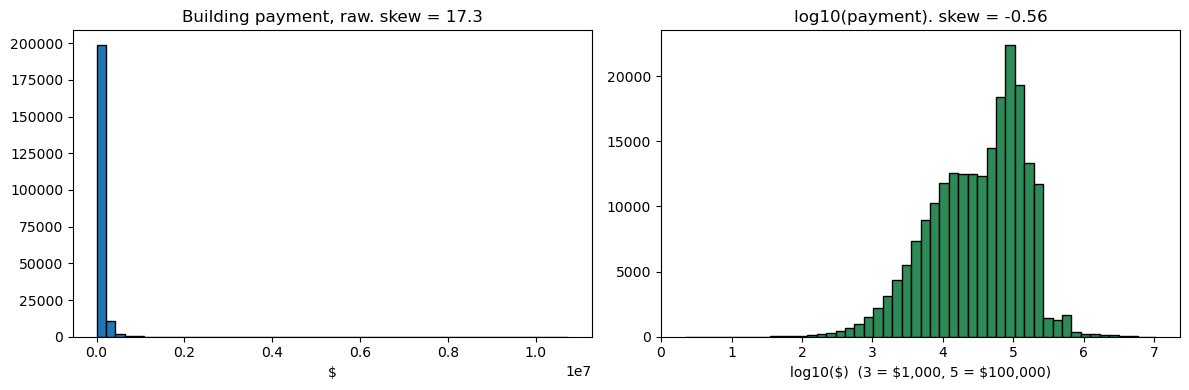

23% of claims were paid $0. We model log(payment) for paid claims.


In [39]:
# Chart (ratio): the RQ1 target, raw vs log
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(pay, bins=50, edgecolor='black'); ax[0].set_title(f'Building payment, raw. skew = {pay.skew():.1f}')
ax[0].set_xlabel('$')
ax[1].hist(np.log10(pay), bins=50, edgecolor='black', color='seagreen'); ax[1].set_title(f'log10(payment). skew = {np.log10(pay).skew():.2f}')
ax[1].set_xlabel('log10($)  (3 = $1,000, 5 = $100,000)')
plt.tight_layout(); plt.show()
print(f"{(work['amountPaidOnBuildingClaim'] == 0).mean():.0%} of claims were paid $0. We model log(payment) for paid claims.")

**Does the new `flood_zone_family` feature matter?** A *nominal* column against a *ratio* column → grouped boxplot.

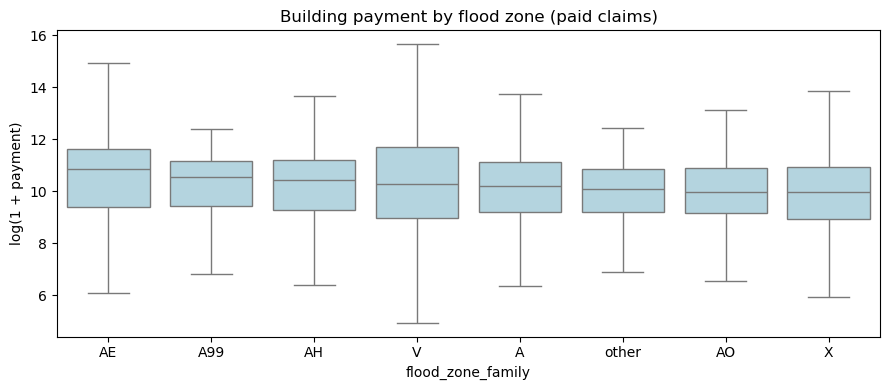

                    count   median
flood_zone_family                 
AE                 157645  50912.0
A99                   656  37681.0
AH                   3080  33497.0
V                    7803  29608.0
A                    7646  27103.0
other                  34  24023.0
AO                   1158  21519.0
X                   34910  21022.0

AE (high risk, the most claims) has the highest median payment. X (low risk) has the lowest,
but it is still the second biggest group. The zone label changes the payment, but does not decide it.


In [40]:
# Chart (nominal vs ratio): does the new flood_zone_family feature matter?
paid_claims = work[work['amountPaidOnBuildingClaim'] > 0]
order = paid_claims.groupby('flood_zone_family')['log_paid_building'].median().sort_values(ascending=False).index
plt.figure(figsize=(9, 4))
sns.boxplot(data=paid_claims, x='flood_zone_family', y='log_paid_building', order=order, showfliers=False, color='lightblue')
plt.title('Building payment by flood zone (paid claims)'); plt.ylabel('log(1 + payment)')
plt.tight_layout(); plt.show()
zone_stats = paid_claims.groupby('flood_zone_family')['amountPaidOnBuildingClaim'].agg(['count', 'median']).round(0)
print(zone_stats.sort_values('median', ascending=False))
print()
print('AE (high risk, the most claims) has the highest median payment. X (low risk) has the lowest,')
print('but it is still the second biggest group. The zone label changes the payment, but does not decide it.')

---
# Section 8: Encoding and Scaling

Every column must be a number before a model can use it.
- **Binary** True/False → 1/0
- **Ordinal** → numbers that keep the order (`map`)
- **Nominal** → one-hot columns (`get_dummies`)

In [41]:
# Binary
for c in ['elevatedBuildingIndicator', 'postFIRMConstructionIndicator', 'primaryResidenceIndicator',
          'rentalPropertyIndicator', 'smallBusinessIndicatorBuilding', 'nonProfitIndicator']:
    work[c] = work[c].astype(int)

# Ordinal: deductible codes -> dollars. The code letters are NOT in dollar order, so we map them.
DEDUCTIBLE_USD = {'0': 500, '1': 1000, '2': 2000, '3': 3000, '4': 4000, '5': 5000, '9': 750, 'A': 10000, 'B': 15000,
                  'C': 20000, 'D': 25000, 'E': 50000, 'F': 1250, 'G': 1500, 'H': 200}
work['bldg_deductible_usd'] = work['buildingDeductibleCode'].map(DEDUCTIBLE_USD)
work['bldg_deductible_usd'] = work['bldg_deductible_usd'].fillna(0)          # 'unknown' is mostly contents-only policies
print(work[['buildingDeductibleCode', 'bldg_deductible_usd']].drop_duplicates().sort_values('bldg_deductible_usd').head(8))
print()
print('Code "9" means $750, code "A" means $10,000. Alphabet order would be wrong.')

      buildingDeductibleCode  bldg_deductible_usd
45                   unknown                  0.0
40                         H                200.0
63301                      0                500.0
71                         1               1000.0
1                          F               1250.0
24                         G               1500.0
3                          2               2000.0
753                        3               3000.0

Code "9" means $750, code "A" means $10,000. Alphabet order would be wrong.


**CRS class is also ordinal** (1 = best flood protection, 10 = none). We keep it as the number 1-10.
Does a better class mean a smaller payment? An *ordinal* column → one point per class, in order.

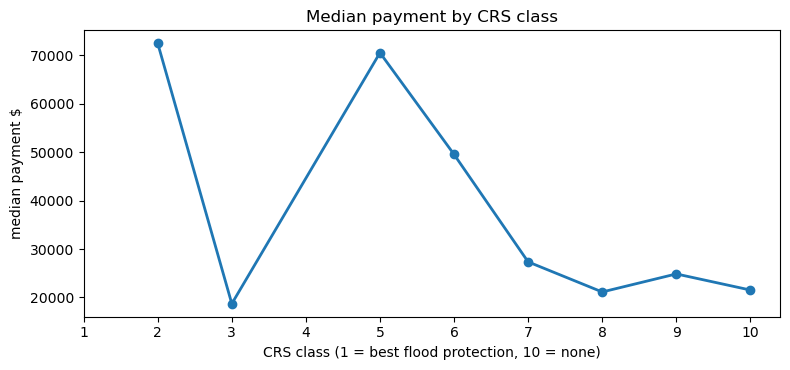

Share of paid claims in Florida, per CRS class (%):
crsClassCode
2.0     84.0
3.0     40.0
5.0     94.0
6.0     72.0
7.0     36.0
8.0     15.0
9.0     24.0
10.0     3.0

The line is not straight. The two high points (class 2 and class 5) are mostly Florida claims.
So CRS class also carries information about location.


In [42]:
# Chart (ordinal): is the order of CRS class useful?
crs_data = paid_claims[paid_claims['crsClassCode_missing'] == 0]
counts = crs_data['crsClassCode'].value_counts()
crs_data = crs_data[crs_data['crsClassCode'].isin(counts[counts >= 300].index)]     # hide classes with very few claims
crs = crs_data.groupby('crsClassCode')['amountPaidOnBuildingClaim'].median()
plt.figure(figsize=(8, 3.8))
plt.plot(crs.index, crs.values, 'o-', lw=2)
plt.xticks(range(1, 11)); plt.xlabel('CRS class (1 = best flood protection, 10 = none)'); plt.ylabel('median payment $')
plt.title('Median payment by CRS class')
plt.tight_layout(); plt.show()
fl_share = (crs_data.assign(fl=crs_data['state'] == 'FL').groupby('crsClassCode')['fl'].mean() * 100).round(0)
print('Share of paid claims in Florida, per CRS class (%):')
print(fl_share.to_string())
print()
print('The line is not straight. The two high points (class 2 and class 5) are mostly Florida claims.')
print('So CRS class also carries information about location.')

In [43]:
# Nominal: one-hot. Keep the 10 biggest states, put the rest in "OTHER", so we don't create 56 columns.
top_states = work['state'].value_counts().head(10).index
work['state_group'] = work['state'].where(work['state'].isin(top_states), 'OTHER')

NOMINAL_FEATURES = ['flood_zone_family', 'foundationType', 'occupancyType', 'state_group', 'basementEnclosureCrawlspaceType',
                    'obstructionType', 'condominiumCoverageTypeCode', 'numberOfFloorsInTheInsuredBuilding']
NUMERIC_FEATURES = ['totalBuildingInsuranceCoverage', 'totalContentsInsuranceCoverage', 'policyCount', 'numberOfUnits',
                    'building_age', 'report_lag_days', 'crsClassCode', 'bldg_deductible_usd', 'loss_month',
                    'latitude', 'longitude', 'elevatedBuildingIndicator', 'postFIRMConstructionIndicator',
                    'primaryResidenceIndicator', 'rentalPropertyIndicator', 'smallBusinessIndicatorBuilding',
                    'nonProfitIndicator', 'is_named_event', 'crsClassCode_missing']

X_all = pd.get_dummies(work[NOMINAL_FEATURES + NUMERIC_FEATURES], columns=NOMINAL_FEATURES, dtype=int)
print(f'Columns before encoding: {len(NOMINAL_FEATURES + NUMERIC_FEATURES)}')
print(f'Columns after encoding : {X_all.shape[1]}')

Columns before encoding: 27
Columns after encoding : 96


In [44]:
from sklearn.preprocessing import StandardScaler

# Log the money and count columns first (they are very skewed), then standardize
LOG_COLS = ['totalBuildingInsuranceCoverage', 'totalContentsInsuranceCoverage', 'policyCount', 'numberOfUnits']
X_scaled = X_all.copy()
X_scaled[LOG_COLS] = np.log1p(X_scaled[LOG_COLS])
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X_scaled), columns=X_all.columns)

print('After StandardScaler every column has mean 0 and std 1:')
print(X_scaled[['totalBuildingInsuranceCoverage', 'building_age', 'crsClassCode']].agg(['mean', 'std']).round(3))
print()
print('We use StandardScaler because PCA, k-means and linear models need columns on the same scale.')
print('Tree models (random forest) do not need scaling.')

After StandardScaler every column has mean 0 and std 1:
      totalBuildingInsuranceCoverage  building_age  crsClassCode
mean                            -0.0           0.0          -0.0
std                              1.0           1.0           1.0

We use StandardScaler because PCA, k-means and linear models need columns on the same scale.
Tree models (random forest) do not need scaling.


---
# Section 9: Feature Selection

The steps:
1. drop near-constant columns (`VarianceThreshold`)
2. drop one of every highly correlated pair (correlation > 0.8)
3. rank by relationship with the target (`SelectKBest`)
4. random forest importance (embedded method)
5. compare models with all columns vs selected columns (`cross_val_score`)

We only use features that are known **when the claim is reported** (policy, building, location, date).

In [45]:
# Rows and targets. We use a sample of 40,000 rows so the models run fast.
rq1 = work['is_paid'] == 1
rq2 = work['high_severity'].notna()

idx1 = work[rq1].sample(40000, random_state=42).index
idx2 = work[rq2].sample(40000, random_state=42).index
X1, y1 = X_all.loc[idx1], work.loc[idx1, 'log_paid_building']
X2, y2 = X_all.loc[idx2], work.loc[idx2, 'high_severity'].astype(int)
print('RQ1 rows:', X1.shape, '  target: log building payment')
print('RQ2 rows:', X2.shape, '  target: high severity,', f'{y2.mean():.0%} are 1')

RQ1 rows: (40000, 96)   target: log building payment
RQ2 rows: (40000, 96)   target: high severity, 20% are 1


## 9.1 Leakage check

First we look at which numeric columns move together with the payment (correlation heatmap).
We use `method='spearman'`: it correlates the *ranks* of the values, so a few huge dollar amounts cannot dominate.

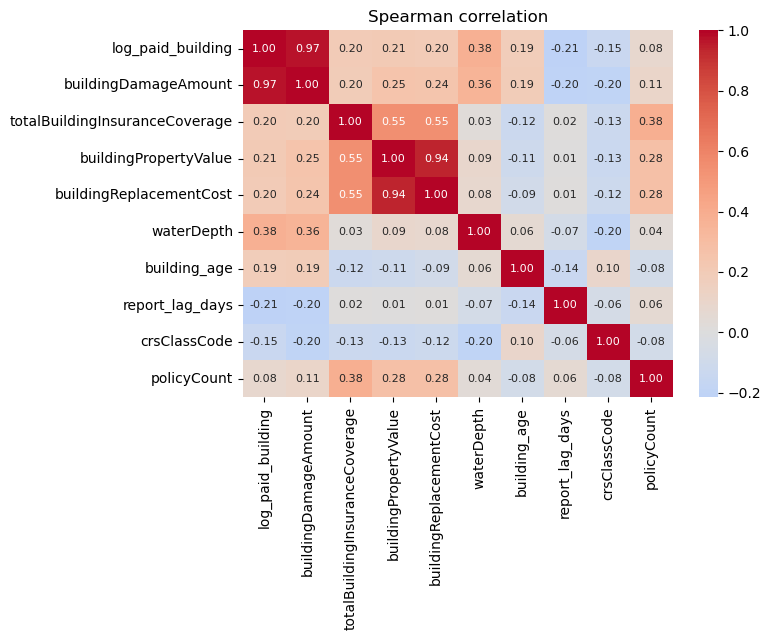

buildingDamageAmount vs payment: 0.97. It would leak the answer for RQ1.
buildingPropertyValue vs buildingReplacementCost: 0.94. One is enough.


In [46]:
# Chart (ratio vs ratio): which numbers move with the payment?
corr_cols = ['log_paid_building', 'buildingDamageAmount', 'totalBuildingInsuranceCoverage', 'buildingPropertyValue',
             'buildingReplacementCost', 'waterDepth', 'building_age', 'report_lag_days', 'crsClassCode', 'policyCount']
plt.figure(figsize=(8, 6.5))
sns.heatmap(work[corr_cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Spearman correlation'); plt.tight_layout(); plt.show()
sp = work[corr_cols].corr(method='spearman')
print(f"buildingDamageAmount vs payment: {sp.loc['buildingDamageAmount', 'log_paid_building']:.2f}. It would leak the answer for RQ1.")
print(f"buildingPropertyValue vs buildingReplacementCost: {sp.loc['buildingPropertyValue', 'buildingReplacementCost']:.2f}. One is enough.")

What happens if we add `buildingDamageAmount` (known only after inspection)?

In [47]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf = RandomForestRegressor(n_estimators=60, min_samples_leaf=20, random_state=42, n_jobs=-1)
r2_normal = cross_val_score(rf, X1, y1, cv=3, scoring='r2').mean()
X1_leak = X1.assign(damage=np.log1p(work.loc[idx1, 'buildingDamageAmount'].fillna(0)))
r2_leak = cross_val_score(rf, X1_leak, y1, cv=3, scoring='r2').mean()
print(f'RQ1 R2 with normal features          : {r2_normal:.3f}')
print(f'RQ1 R2 with buildingDamageAmount too : {r2_leak:.3f}')
print()
print('The score jumps. Damage is almost the payment, so the model is reading the answer.')
print('This is leakage. We do NOT use damage, payments or adjuster fields as features.')

RQ1 R2 with normal features          : 0.447
RQ1 R2 with buildingDamageAmount too : 0.943

The score jumps. Damage is almost the payment, so the model is reading the answer.
This is leakage. We do NOT use damage, payments or adjuster fields as features.


## 9.2 Drop near-constant columns

In [48]:
from sklearn.feature_selection import VarianceThreshold

vt = VarianceThreshold(threshold=0.01)
vt.fit(X1)
kept_vt = X1.columns[vt.get_support()]
print(f'Columns before : {X1.shape[1]}')
print(f'Columns after  : {len(kept_vt)}')
print('Dropped:', list(X1.columns[~vt.get_support()]))

Columns before : 96
Columns after  : 64
Dropped: ['nonProfitIndicator', 'flood_zone_family_A99', 'flood_zone_family_AO', 'flood_zone_family_other', 'occupancyType_2.0', 'occupancyType_3.0', 'occupancyType_4.0', 'occupancyType_6.0', 'occupancyType_16.0', 'occupancyType_17.0', 'occupancyType_19.0', 'obstructionType_20', 'obstructionType_24', 'obstructionType_30', 'obstructionType_34', 'obstructionType_40', 'obstructionType_60', 'obstructionType_70', 'obstructionType_80', 'obstructionType_90', 'obstructionType_92', 'obstructionType_94', 'obstructionType_95', 'obstructionType_96', 'obstructionType_97', 'obstructionType_98', 'obstructionType_unknown', 'condominiumCoverageTypeCode_H', 'condominiumCoverageTypeCode_L', 'condominiumCoverageTypeCode_U', 'numberOfFloorsInTheInsuredBuilding_4.0', 'numberOfFloorsInTheInsuredBuilding_6.0']


## 9.3 Drop one of every highly correlated pair

In [49]:
corr = X1[kept_vt].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False).head(8).reset_index()
pairs.columns = ['column A', 'column B', 'correlation']
print('Most correlated pairs:')
print(pairs.round(3).to_string(index=False))

THRESHOLD = 0.80
to_drop = [c for c in upper.columns if any(upper[c] > THRESHOLD)]
print()
print(f'Columns dropped (correlation > {THRESHOLD}):', to_drop)
X1_dec = X1[kept_vt].drop(columns=to_drop)
X2_dec = X2[kept_vt].drop(columns=to_drop)
print('Columns left:', X1_dec.shape[1])

Most correlated pairs:
                              column A                               column B  correlation
        totalBuildingInsuranceCoverage                            policyCount        0.964
             elevatedBuildingIndicator         obstructionType_not_applicable        0.955
                    occupancyType_15.0          condominiumCoverageTypeCode_N        0.935
                    occupancyType_14.0 numberOfFloorsInTheInsuredBuilding_5.0        0.933
                    occupancyType_15.0          condominiumCoverageTypeCode_A        0.926
                      foundationType_0                      occupancyType_1.0        0.909
         condominiumCoverageTypeCode_A          condominiumCoverageTypeCode_N        0.871
numberOfFloorsInTheInsuredBuilding_1.0 numberOfFloorsInTheInsuredBuilding_2.0        0.793

Columns dropped (correlation > 0.8): ['policyCount', 'occupancyType_1.0', 'obstructionType_not_applicable', 'condominiumCoverageTypeCode_A', 'condominiumCove

## 9.4 Rank by relationship with the target (filter method)
- RQ1 (number target): `f_regression`
- RQ2 (0/1 target): `f_classif`

In [50]:
from sklearn.feature_selection import SelectKBest, f_regression, f_classif

K = 15
sel1 = SelectKBest(score_func=f_regression, k=K).fit(X1_dec, y1)
sel2 = SelectKBest(score_func=f_classif, k=K).fit(X2_dec, y2)
top1 = X1_dec.columns[sel1.get_support()].tolist()
top2 = X2_dec.columns[sel2.get_support()].tolist()

scores = pd.DataFrame({'RQ1 F-score': pd.Series(sel1.scores_, index=X1_dec.columns),
                       'RQ2 F-score': pd.Series(sel2.scores_, index=X2_dec.columns)})
print('Top 10 for RQ1:')
print(scores['RQ1 F-score'].sort_values(ascending=False).head(10).round(0).to_string())
print()
print('Top 10 for RQ2:')
print(scores['RQ2 F-score'].sort_values(ascending=False).head(10).round(0).to_string())

Top 10 for RQ1:
foundationType_1                 7739.0
state_group_FL                   3818.0
elevatedBuildingIndicator        3635.0
latitude                         2578.0
postFIRMConstructionIndicator    2216.0
bldg_deductible_usd              2094.0
is_named_event                   2057.0
crsClassCode                     1618.0
state_group_OTHER                1207.0
foundationType_6                 1202.0

Top 10 for RQ2:
state_group_FL               2965.0
foundationType_1             2887.0
latitude                     1574.0
is_named_event               1299.0
bldg_deductible_usd          1263.0
crsClassCode                 1237.0
elevatedBuildingIndicator    1104.0
flood_zone_family_AE          960.0
crsClassCode_missing          815.0
flood_zone_family_X           801.0


## 9.5 Random forest importance (embedded method)

A filter looks at one column at a time. A random forest can also see curves and combinations.

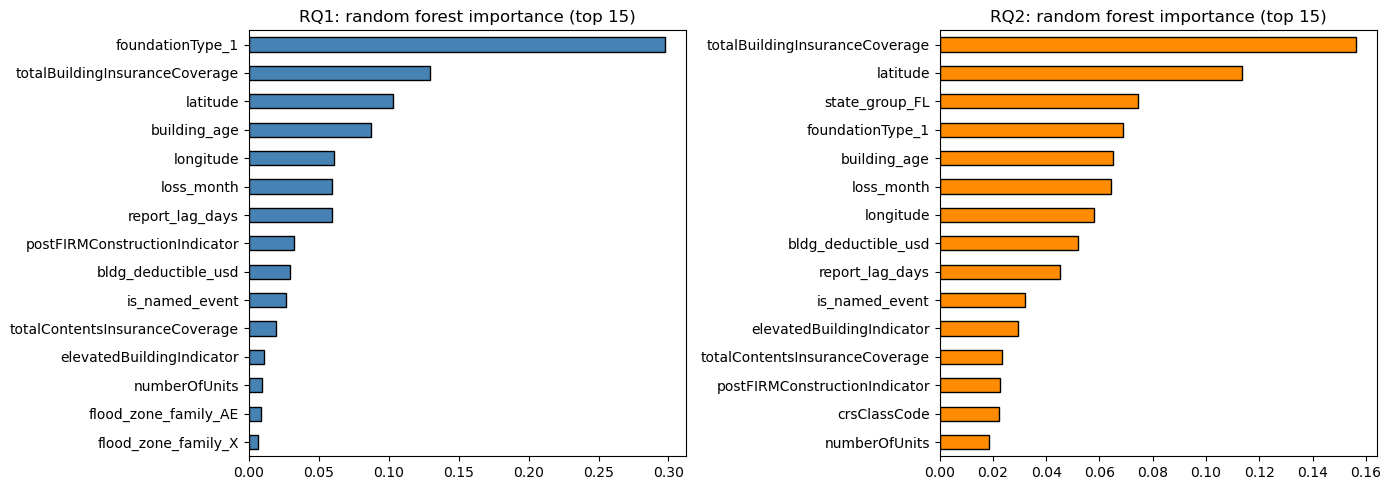

Overlap with SelectKBest top 15:
   RQ1: 6 of 15
   RQ2: 9 of 15


In [51]:
rf1 = RandomForestRegressor(n_estimators=100, min_samples_leaf=20, random_state=42, n_jobs=-1).fit(X1_dec, y1)
rf2 = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight='balanced', random_state=42, n_jobs=-1).fit(X2_dec, y2)
imp1 = pd.Series(rf1.feature_importances_, index=X1_dec.columns).sort_values(ascending=False)
imp2 = pd.Series(rf2.feature_importances_, index=X2_dec.columns).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp1.head(15)[::-1].plot.barh(ax=ax[0], color='steelblue', edgecolor='black'); ax[0].set_title('RQ1: random forest importance (top 15)')
imp2.head(15)[::-1].plot.barh(ax=ax[1], color='darkorange', edgecolor='black'); ax[1].set_title('RQ2: random forest importance (top 15)')
plt.tight_layout(); plt.show()

print('Overlap with SelectKBest top 15:')
print('   RQ1:', len(set(imp1.head(K).index) & set(top1)), 'of', K)
print('   RQ2:', len(set(imp2.head(K).index) & set(top2)), 'of', K)

## 9.6 Does selection help? Same model, different inputs

In [52]:
def score_rq1(cols, label):
    s = cross_val_score(RandomForestRegressor(n_estimators=60, min_samples_leaf=20, random_state=42, n_jobs=-1),
                        X1_dec[cols], y1, cv=3, scoring='r2')
    print(f'{label:32s} cols={len(cols):>3}   R2      = {s.mean():.3f} (+/- {s.std():.3f})')

def score_rq2(cols, label):
    s = cross_val_score(RandomForestClassifier(n_estimators=60, min_samples_leaf=20, class_weight='balanced', random_state=42, n_jobs=-1),
                        X2_dec[cols], y2, cv=3, scoring='roc_auc')
    print(f'{label:32s} cols={len(cols):>3}   ROC-AUC = {s.mean():.3f} (+/- {s.std():.3f})')

print('RQ1 (3-fold cross validation)')
score_rq1(list(X1_dec.columns), 'All columns')
score_rq1(top1, f'Top {K} by SelectKBest')
score_rq1(list(imp1.head(K).index), f'Top {K} by random forest')
print()
print('RQ2 (3-fold cross validation)')
score_rq2(list(X2_dec.columns), 'All columns')
score_rq2(top2, f'Top {K} by SelectKBest')
score_rq2(list(imp2.head(K).index), f'Top {K} by random forest')

RQ1 (3-fold cross validation)


All columns                      cols= 58   R2      = 0.447 (+/- 0.010)


Top 15 by SelectKBest            cols= 15   R2      = 0.335 (+/- 0.007)


Top 15 by random forest          cols= 15   R2      = 0.443 (+/- 0.010)

RQ2 (3-fold cross validation)


All columns                      cols= 58   ROC-AUC = 0.874 (+/- 0.001)


Top 15 by SelectKBest            cols= 15   ROC-AUC = 0.826 (+/- 0.002)


Top 15 by random forest          cols= 15   ROC-AUC = 0.874 (+/- 0.001)


**What this shows:** the top 15 by random forest score almost the same as all columns, with far fewer columns.
So feature selection makes the model **simpler** without losing much. It does not make it much better.
The R² for RQ1 is about 0.45: information known before the inspection explains less than half of the payment. That is an honest result.
Also note: cross validation here mixes claims from the same storm in training and testing. Testing on new years (2024-2025) gives a lower R², about 0.33.

## 9.7 Final feature lists

In [53]:
FINAL_RQ1 = list(imp1.head(K).index)
FINAL_RQ2 = list(imp2.head(K).index)
FINAL_RQ3 = ['flood_zone_family', 'foundationType', 'building_age', 'numberOfFloorsInTheInsuredBuilding',
             'occupancyType', 'crsClassCode', 'totalBuildingInsuranceCoverage']
print('RQ1 features:', FINAL_RQ1)
print()
print('RQ2 features:', FINAL_RQ2)
print()
print('RQ3 features (chosen by meaning, no target):', FINAL_RQ3)

RQ1 features: ['foundationType_1', 'totalBuildingInsuranceCoverage', 'latitude', 'building_age', 'longitude', 'loss_month', 'report_lag_days', 'postFIRMConstructionIndicator', 'bldg_deductible_usd', 'is_named_event', 'totalContentsInsuranceCoverage', 'elevatedBuildingIndicator', 'numberOfUnits', 'flood_zone_family_AE', 'flood_zone_family_X']

RQ2 features: ['totalBuildingInsuranceCoverage', 'latitude', 'state_group_FL', 'foundationType_1', 'building_age', 'loss_month', 'longitude', 'bldg_deductible_usd', 'report_lag_days', 'is_named_event', 'elevatedBuildingIndicator', 'totalContentsInsuranceCoverage', 'postFIRMConstructionIndicator', 'crsClassCode', 'numberOfUnits']

RQ3 features (chosen by meaning, no target): ['flood_zone_family', 'foundationType', 'building_age', 'numberOfFloorsInTheInsuredBuilding', 'occupancyType', 'crsClassCode', 'totalBuildingInsuranceCoverage']


In [54]:
print('Check: how strongly is foundationType linked to elevatedBuildingIndicator?')
print(pd.crosstab(work['foundationType'], work['elevatedBuildingIndicator']))
print()
slab = work['foundationType'] == '1'
print(f"Slab (code 1): only {work.loc[slab, 'elevatedBuildingIndicator'].mean():.1%} are elevated.")
print(f"Elevated foundations (codes 4-6): {work.loc[work['foundationType'].isin(['4', '5', '6']), 'elevatedBuildingIndicator'].mean():.0%} are elevated.")
print('The two columns are strongly linked, but not identical. We keep foundationType (more detail)')
print('and leave out elevatedBuildingIndicator, so the same idea does not count twice in the clustering.')
print()
print('Proof: latitude mostly tells us the state')
print(work.groupby('state_group')['latitude'].median().round(1).sort_values().to_string())
print('Each state has its own typical latitude. Clustering on latitude would mostly separate states.')

Check: how strongly is foundationType linked to elevatedBuildingIndicator?
elevatedBuildingIndicator       0      1
foundationType                          
0                           19095   7069
1                          152358   1152
2                           23802    430
3                           11439   8819
4                            3840  12882
5                            4837  14475
6                            4148  12224

Slab (code 1): only 0.8% are elevated.
Elevated foundations (codes 4-6): 76% are elevated.
The two columns are strongly linked, but not identical. We keep foundationType (more detail)
and leave out elevatedBuildingIndicator, so the same idea does not count twice in the clustering.

Proof: latitude mostly tells us the state
state_group
FL       27.4
TX       29.6
LA       30.1
AL       30.3
SC       33.6
NC       35.3
KY       37.7
OTHER    38.7
PA       40.2
NJ       40.7
NY       40.8
Each state has its own typical latitude. Clustering on latitude 

**RQ3 note:** clustering has no target, so we choose columns that describe the **building's flood risk**.
We leave out payment and damage (we use them later to check the clusters).
We leave out latitude/longitude, otherwise the clusters would only be "Florida vs. the rest".
`elevatedBuildingIndicator` is left out because it is strongly linked to `foundationType` (proof above).

---
# Section 10: Summary

In [55]:
print('SHAPE OF THE DATA')
print(f'   raw (2020-2025)            : {before:,} rows x 84 columns')
print(f'   after cleaning             : {len(work):,} rows x {work.shape[1]} columns')
print(f'   model features (encoded)   : {X_all.shape[1]} columns')
print(f'   after feature selection    : {K} columns per research question')

work.to_parquet('outputs/nfip_claims_simple_clean.parquet', index=False)
# location keys for the same rows, in the same order (used by the regional analysis, not as model features here)
df.loc[work.index, ['id', 'countyCode', 'censusGeoid', 'reportedZipCode']].to_parquet('outputs/nfip_claims_simple_keys.parquet', index=False)

import json
feature_lists = {'NOMINAL_FEATURES': NOMINAL_FEATURES, 'NUMERIC_FEATURES': NUMERIC_FEATURES, 'LOG_COLS': LOG_COLS,
                 'RQ1': FINAL_RQ1, 'RQ2': FINAL_RQ2, 'RQ3': FINAL_RQ3}
with open('outputs/simple_feature_lists.json', 'w') as f:
    json.dump(feature_lists, f, indent=2)
print()
print('Saved: outputs/nfip_claims_simple_clean.parquet and outputs/simple_feature_lists.json')

SHAPE OF THE DATA
   raw (2020-2025)            : 277,033 rows x 84 columns
   after cleaning             : 276,570 rows x 63 columns
   model features (encoded)   : 96 columns
   after feature selection    : 15 columns per research question



Saved: outputs/nfip_claims_simple_clean.parquet and outputs/simple_feature_lists.json


| Step | What we did | Why |
|---|---|---|
| Hidden missing | 99" water depth, $0 building value, $1 damage → NaN | they are codes, not real values |
| Missing values | 0 / "unknown" / mode / median / state median; target not filled | each kind of blank needs a different fix |
| Duplicates | 463 repeated claims removed | the same claim was entered twice |
| Dropped columns | 41 (empty, constant, IDs, repeats, leakage) | they cannot help, or they cheat |
| Outliers | kept, used log transform | big claims are real |
| Noise | impossible dates → NaN, negative payments → 0 | wrong by definition |
| New features | building age, report lag, flood zone family, named event, targets | ideas from the flood insurance domain |
| Encoding | binary → 0/1, ordinal → map, nominal → one-hot | nominal and ordinal need different treatment |
| Scaling | log1p + StandardScaler | needed for PCA, k-means, linear models |
| Feature selection | VarianceThreshold → correlation > 0.8 → SelectKBest → random forest | fewer columns, almost the same score |

**Charts used, and where**

| Chart | Column type | Section | What it decided |
|---|---|---|---|
| Missing values per column (bar) | any | 2.1 | which columns need a missing-value plan |
| Claims per month (bar, time order) | interval (date) | 0 | storms drive the data |
| Top 10 states (bar) | nominal | 0 | Florida has most claims; keep top 10 states for encoding |
| Correlation with the payment (bars) | ratio + 0/1 flags | 4.2 | which columns leak the answer |
| Building value filled 3 ways (histograms) | ratio | 5.1 | state median instead of one global median |
| Payment raw vs log (boxplots) | ratio | 6 | big payments are real outliers; use log |
| Payment raw vs log (histograms) | ratio | 7 | RQ1 target is log(payment) |
| Payment by flood zone (grouped boxplot) | nominal + ratio | 7 | `flood_zone_family` is a useful feature |
| Median payment by CRS class (points in order) | ordinal | 8 | CRS order is not simple; it also carries location |
| Correlation heatmap | ratio | 9.1 | damage leaks the answer; drop one of value / replacement cost |
| Random forest importance (bars) | features | 9.5 | final feature lists |

**Main lessons**
1. Many blanks are not "missing". They mean "not applicable" (no payment, no contents insurance).
2. A few hurricanes create most claims, and Florida has more than half. Our results mostly describe Florida hurricane claims.
3. Payment and damage columns leak the answer. We only use information known when the claim is reported.
4. Feature selection made the models simpler, not much better.